# Foundations of Deep Learning — Exercise Sheet 1 (Part B: Programming)

This notebook contains Task 4 of Exercise Sheet 1.

* Fill in all parts marked with `TODO`.
* Before the presentation: **Restart the kernel and run all cells** (`Kernel → Restart & Run All`) so that all outputs are visible.
* You need `numpy` and `matplotlib`. On Google Colab everything is pre-installed.
* Every group member must be able to explain every line of code in this notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

---
## Task 4: Perceptrons in NumPy

### 4(a) A vectorized perceptron

Implement the step function $h$ and the perceptron $c(\mathbf{x}) = h(\theta_0 + \theta_1 x_1 + \theta_2 x_2)$ from Task 2.
`perceptron` should classify **all** rows of `X` at once — do not use a loop.

In [2]:
def step(z):
    """Element-wise step function: 1 if z >= 0, else 0 (as integer array)."""
    return (np.asarray(z) >= 0).astype(int)


def perceptron(X, theta):
    """
    X:     array of shape (n, 2), one data point per row
    theta: array of shape (3,) = (theta_0, theta_1, theta_2)
    returns: array of shape (n,) with predictions in {0, 1}
    """
    return step(theta[0] + X @ theta[1:])

Check your answer to Task 2(a):

In [3]:
points = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])
print(perceptron(points, np.array([-1.0, 2.0, 1.0])))

[0 1 1 1]


The helper below plots the decision regions of any classifier `predict(X)` together with labeled data points.
You do not need to change it.

In [4]:
def plot_decision_regions(predict, X, y, title="", ax=None, lim=(-0.5, 1.5)):
    """Colors the plane by the prediction of `predict` and draws the points X with labels y."""
    if ax is None:
        ax = plt.gca()
    grid = np.linspace(*lim, 300)
    xx, yy = np.meshgrid(grid, grid)
    zz = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#9ecae1", "#fdae6b"], alpha=0.6)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="#08519c", marker="o", s=80, label="class 0", edgecolor="k")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="#d94801", marker="s", s=80, label="class 1", edgecolor="k")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    ax.set_title(title)

### 4(b) Logical functions

Enter your parameters for **AND**, **OR** and **NAND** from Task 2(b) and visualize them.

AND correct: True
OR correct: True
NAND correct: True


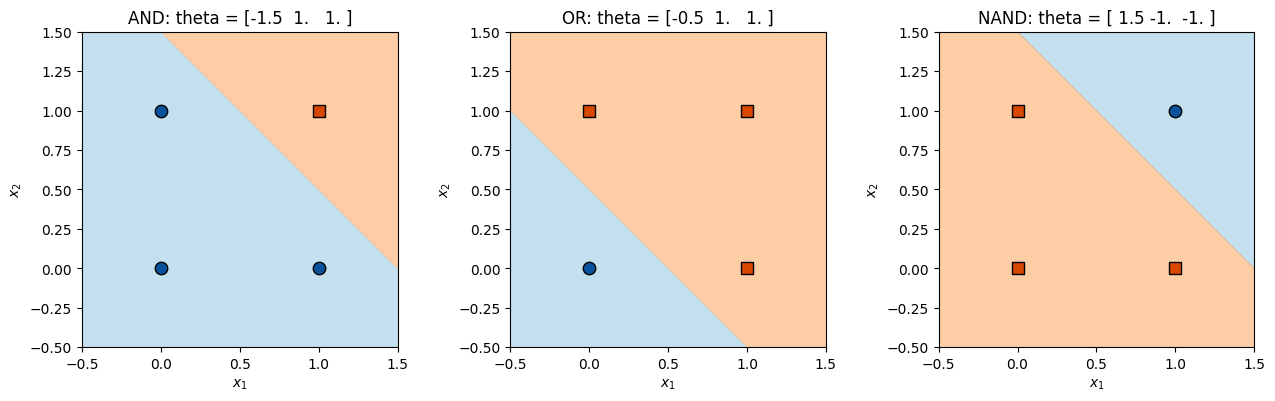

In [5]:
X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and  = np.array([0, 0, 0, 1])
y_or   = np.array([0, 1, 1, 1])
y_nand = np.array([1, 1, 1, 0])

# Parameters (theta_0, theta_1, theta_2)
theta_and  = np.array([-1.5, 1.0, 1.0])
theta_or   = np.array([-0.5, 1.0, 1.0])
theta_nand = np.array([1.5, -1.0, -1.0])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, theta, y, name in zip(axes, [theta_and, theta_or, theta_nand], [y_and, y_or, y_nand], ["AND", "OR", "NAND"]):
    plot_decision_regions(lambda Z: perceptron(Z, theta), X_bool, y, title=f"{name}: theta = {theta}", ax=ax)
    print(name, "correct:", np.array_equal(perceptron(X_bool, theta), y))
plt.tight_layout()
plt.show()

---
**Done!** Restart the kernel and run all cells before the presentation.